# 01 - Data Preparation: COCO val2017 Image-Caption Pairs

Pipeline:
1. Download COCO val2017 (5,000 images, ~25k captions)
2. Clean captions (normalize, dedupe, length and CLIP token limits) and keep one caption per image
3. Filter images by resolution and aspect ratio
4. CLIP-score filtering (drop the lowest-alignment pairs)
5. Center-crop to 512x512 and save in HF ImageFolder format (`metadata.jsonl`)

Raw data and processing live on local Colab disk (fast). The final dataset is zipped to Drive once, because reading thousands of small files through Drive is slow.

**Runtime:** set Runtime > Change runtime type > T4 GPU before running.

## Setup

In [18]:
import os
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/t2i_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Must be set before importing transformers/diffusers so model weights cache on Drive
os.environ["HF_HOME"] = "/content/hf_cache"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
!pip install -q diffusers accelerate

In [20]:
import torch

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > T4 GPU"
DEVICE = "cuda"
print(torch.cuda.get_device_name(0))
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Tesla T4
VRAM: 15.6 GB


In [21]:
RAW_DIR = "/content/coco_raw"
LOCAL_ROOT = "/content/coco_clean"
TRAIN_DIR = f"{LOCAL_ROOT}/train"
DRIVE_DATA = f"{PROJECT_DIR}/data"
FIG_DIR = f"{PROJECT_DIR}/outputs/figures"

CLIP_ID = "openai/clip-vit-large-patch14"  # same CLIP family as the SD 1.5 text encoder

MIN_WORDS, MAX_WORDS = 5, 40
MIN_SIDE = 256
MAX_ASPECT = 2.0
CLIP_DROP_PCT = 15
TARGET_SIZE = 512
SEED = 42

for d in [TRAIN_DIR, DRIVE_DATA, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

## 1. Download COCO val2017

In [22]:
%%bash
mkdir -p /content/coco_raw && cd /content/coco_raw
if [ ! -d val2017 ]; then
  wget -q http://images.cocodataset.org/zips/val2017.zip && unzip -q val2017.zip && rm val2017.zip
fi
if [ ! -d annotations ]; then
  wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip && unzip -q annotations_trainval2017.zip && rm annotations_trainval2017.zip
fi
echo "images: $(ls val2017 | wc -l)"

images: 5000


In [23]:
import json
from collections import defaultdict

with open(f"{RAW_DIR}/annotations/captions_val2017.json") as f:
    cap_json = json.load(f)

images = {im["id"]: im for im in cap_json["images"]}
captions = defaultdict(list)
for ann in cap_json["annotations"]:
    captions[ann["image_id"]].append(ann["caption"])

print(f"images: {len(images)}, captions: {len(cap_json['annotations'])}")

images: 5000, captions: 25014


Primary supercategory per image (from the largest annotated object). Used later to check whether text embeddings cluster by content.

In [24]:
with open(f"{RAW_DIR}/annotations/instances_val2017.json") as f:
    inst_json = json.load(f)

cat_to_super = {c["id"]: c["supercategory"] for c in inst_json["categories"]}
largest = {}
for ann in inst_json["annotations"]:
    iid = ann["image_id"]
    if iid not in largest or ann["area"] > largest[iid][0]:
        largest[iid] = (ann["area"], cat_to_super[ann["category_id"]])

primary_category = {iid: v[1] for iid, v in largest.items()}
del inst_json

## 2. Caption cleaning

In [25]:
import re
from transformers import CLIPTokenizer

tokenizer = CLIPTokenizer.from_pretrained(CLIP_ID)

def normalize(text):
    text = re.sub(r"\s+", " ", text).strip().rstrip(" .")
    return text[:1].upper() + text[1:]

def caption_ok(text):
    n_words = len(text.split())
    if not (MIN_WORDS <= n_words <= MAX_WORDS):
        return False
    return len(tokenizer(text).input_ids) <= tokenizer.model_max_length

stats = {"images_total": len(images), "captions_total": len(cap_json["annotations"])}
records = []
dropped_caption = 0

for image_id, cap_list in captions.items():
    cleaned = list(dict.fromkeys(normalize(c) for c in cap_list))
    valid = [c for c in cleaned if caption_ok(c)]
    if not valid:
        dropped_caption += 1
        continue
    im = images[image_id]
    records.append({
        "image_id": image_id,
        "coco_file": im["file_name"],
        "width": im["width"],
        "height": im["height"],
        "text": max(valid, key=len),  # longest valid caption is usually the most descriptive
        "category": primary_category.get(image_id, "none"),
    })

stats["dropped_no_valid_caption"] = dropped_caption
print(f"kept after caption cleaning: {len(records)} (dropped {dropped_caption})")

kept after caption cleaning: 5000 (dropped 0)


## 3. Image filtering (resolution and aspect ratio)

In [26]:
!rm -rf /content/drive/MyDrive/t2i_project/hf_cache

In [27]:
before = len(records)
records = [
    r for r in records
    if min(r["width"], r["height"]) >= MIN_SIDE
    and max(r["width"], r["height"]) / min(r["width"], r["height"]) <= MAX_ASPECT
]
stats["dropped_image_filter"] = before - len(records)
print(f"kept after image filter: {len(records)} (dropped {before - len(records)})")

kept after image filter: 4926 (dropped 74)


## 4. CLIP-score filtering

Cosine similarity between CLIP image and text embeddings. CLIPScore = 100 * max(cos, 0).

In [28]:
import numpy as np
from PIL import Image
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=torch.float16).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

BATCH = 64
cosines = []
for i in tqdm(range(0, len(records), BATCH)):
    batch = records[i:i + BATCH]
    imgs = [Image.open(f"{RAW_DIR}/val2017/{r['coco_file']}").convert("RGB") for r in batch]
    inputs = clip_proc(text=[r["text"] for r in batch], images=imgs,
                       return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    with torch.no_grad():
        out = clip_model(input_ids=inputs["input_ids"],
                         attention_mask=inputs["attention_mask"],
                         pixel_values=inputs["pixel_values"].half())
    img_emb = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    txt_emb = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    cosines.extend((img_emb * txt_emb).sum(dim=-1).float().cpu().tolist())

for r, c in zip(records, cosines):
    r["clip_score"] = round(100 * max(c, 0.0), 2)

scores = np.array([r["clip_score"] for r in records])
threshold = float(np.percentile(scores, CLIP_DROP_PCT))
print(f"CLIPScore mean {scores.mean():.2f}, median {np.median(scores):.2f}, "
      f"{CLIP_DROP_PCT}th percentile threshold {threshold:.2f}")

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

  0%|          | 0/77 [00:00<?, ?it/s]

CLIPScore mean 26.24, median 26.23, 15th percentile threshold 22.34


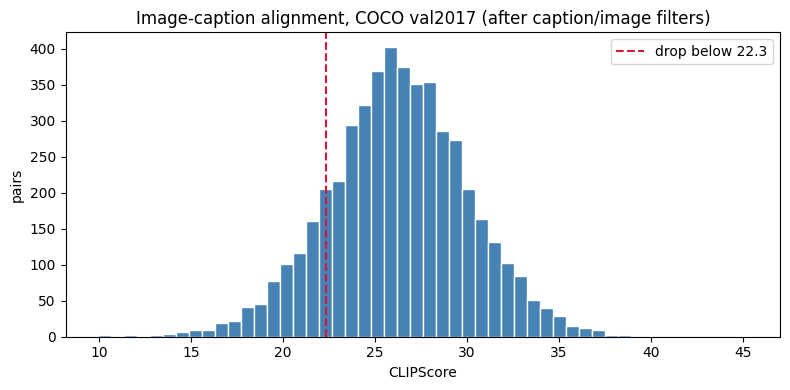

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores, bins=50, color="steelblue", edgecolor="white")
ax.axvline(threshold, color="crimson", linestyle="--", label=f"drop below {threshold:.1f}")
ax.set_xlabel("CLIPScore")
ax.set_ylabel("pairs")
ax.set_title("Image-caption alignment, COCO val2017 (after caption/image filters)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/clip_score_hist.png", dpi=150)
plt.show()

Lowest vs highest scoring pairs. Check that the low end really is misaligned before trusting the filter.

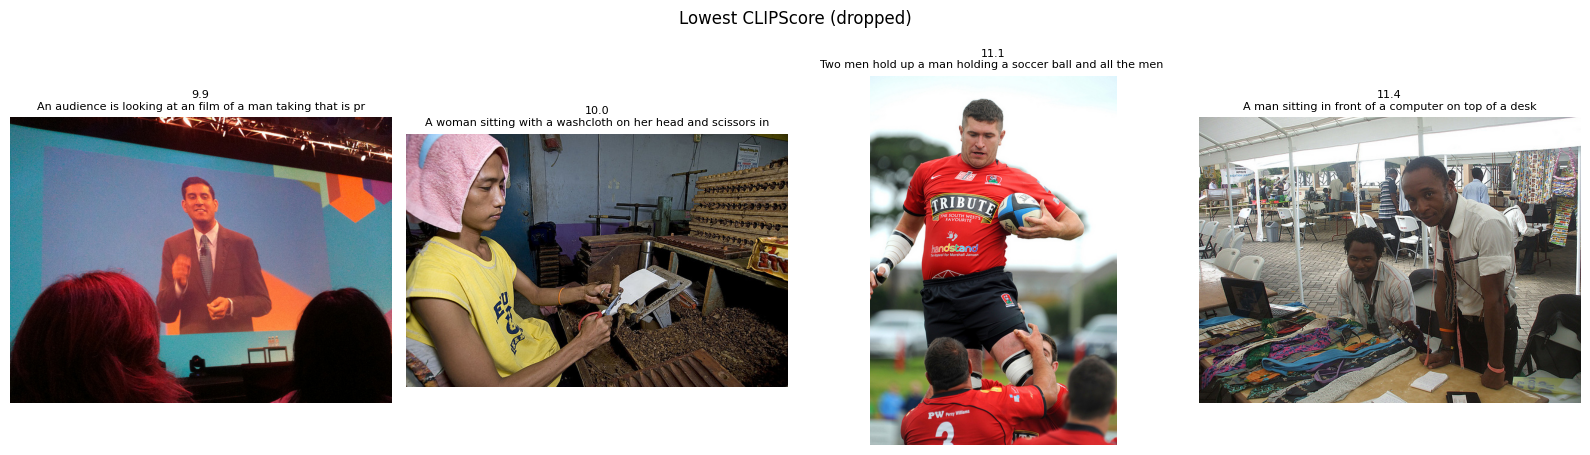

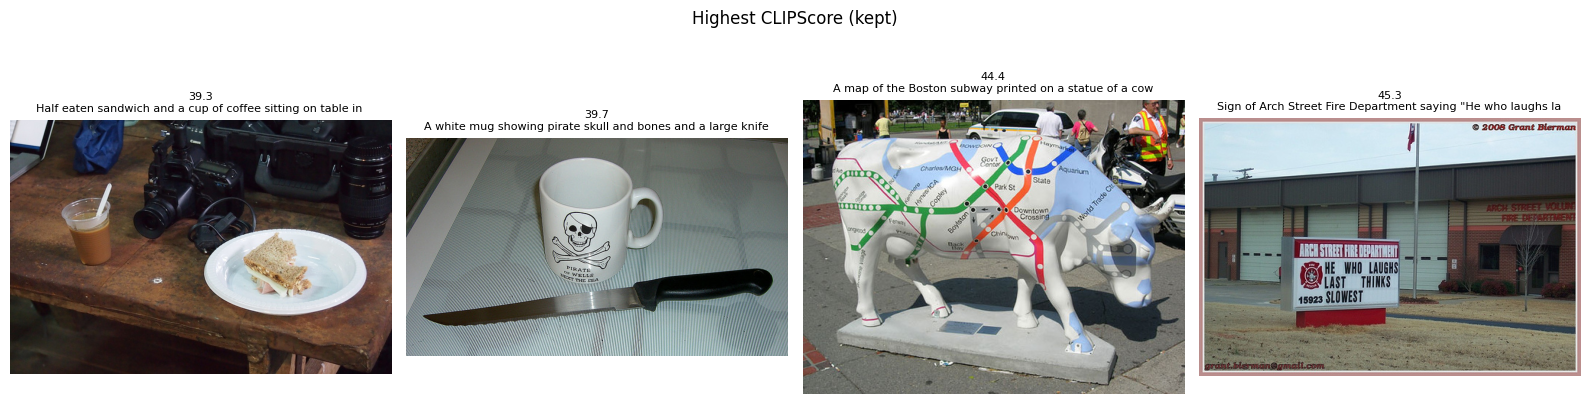

In [30]:
def show_pairs(rows, title):
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4.6))
    for ax, r in zip(axes, rows):
        ax.imshow(Image.open(f"{RAW_DIR}/val2017/{r['coco_file']}"))
        ax.set_title(f"{r['clip_score']:.1f}\n{r['text'][:60]}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

ranked = sorted(records, key=lambda r: r["clip_score"])
show_pairs(ranked[:4], "Lowest CLIPScore (dropped)")
show_pairs(ranked[-4:], "Highest CLIPScore (kept)")

In [31]:
before = len(records)
records = [r for r in records if r["clip_score"] >= threshold]
stats["dropped_clip_filter"] = before - len(records)
stats["clip_threshold"] = threshold
stats["final_pairs"] = len(records)
print(f"final pairs: {len(records)}")

del clip_model
torch.cuda.empty_cache()

final pairs: 4189


## 5. Resize, save, and archive to Drive

In [32]:
def center_crop_resize(img, size):
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((size, size), Image.BICUBIC)

os.makedirs(f"{TRAIN_DIR}/images", exist_ok=True)
with open(f"{TRAIN_DIR}/metadata.jsonl", "w") as f:
    for r in tqdm(records):
        out_name = f"images/{r['image_id']:012d}.jpg"
        img = Image.open(f"{RAW_DIR}/val2017/{r['coco_file']}").convert("RGB")
        center_crop_resize(img, TARGET_SIZE).save(f"{TRAIN_DIR}/{out_name}", quality=95)
        f.write(json.dumps({
            "file_name": out_name,
            "text": r["text"],
            "image_id": r["image_id"],
            "category": r["category"],
            "clip_score": r["clip_score"],
        }) + "\n")

with open(f"{DRIVE_DATA}/stats.json", "w") as f:
    json.dump(stats, f, indent=2)

  0%|          | 0/4189 [00:00<?, ?it/s]

In [33]:
import shutil

archive = shutil.make_archive(f"{DRIVE_DATA}/coco_clean", "zip", LOCAL_ROOT)
shutil.copy(f"{TRAIN_DIR}/metadata.jsonl", f"{DRIVE_DATA}/metadata.jsonl")
print(f"archive: {archive} ({os.path.getsize(archive) / 1e6:.0f} MB)")

archive: /content/drive/MyDrive/t2i_project/data/coco_clean.zip (467 MB)


## 6. Summary (use these numbers in the proposal)

In [34]:
import pandas as pd

print(json.dumps(stats, indent=2))
df = pd.read_json(f"{TRAIN_DIR}/metadata.jsonl", lines=True)
print("\ncaption length (words):")
print(df.text.str.split().str.len().describe().round(1))
print("\nprimary category distribution:")
print(df.category.value_counts())

{
  "images_total": 5000,
  "captions_total": 25014,
  "dropped_no_valid_caption": 0,
  "dropped_image_filter": 74,
  "dropped_clip_filter": 737,
  "clip_threshold": 22.34,
  "final_pairs": 4189
}

caption length (words):
count    4189.0
mean       12.9
std         3.1
min         8.0
25%        11.0
50%        12.0
75%        14.0
max        38.0
Name: text, dtype: float64

primary category distribution:
category
person        1337
animal         641
vehicle        568
furniture      503
food           209
outdoor        208
indoor         175
appliance      165
electronic     130
kitchen         76
accessory       71
sports          66
none            40
Name: count, dtype: int64
